In [1]:
# Step 1: Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# Step 2: Load dataset
df = pd.read_csv("C:/Users/prath/Downloads/ML_PRAC/Churn_Modelling.csv")

In [5]:
# Step 3: Display first five records
print("First Five Records:")
print(df.head())

First Five Records:
   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        113931.57       1  
3         93826.63    

In [ ]:
# Step 4: Display dataset information
print("\nDataset Information:")
df.info()

In [ ]:
# Step 5: Display number of rows and columns
print("\nDataset Shape:")
print(df.shape)

In [ ]:
# Step 6: Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

In [6]:
# Step 7: Display statistical description
print("\nStatistical Description:")
print(df.describe())


Statistical Description:
         RowNumber    CustomerId   CreditScore           Age        Tenure  \
count  10000.00000  1.000000e+04  10000.000000  10000.000000  10000.000000   
mean    5000.50000  1.569094e+07    650.528800     38.921800      5.012800   
std     2886.89568  7.193619e+04     96.653299     10.487806      2.892174   
min        1.00000  1.556570e+07    350.000000     18.000000      0.000000   
25%     2500.75000  1.562853e+07    584.000000     32.000000      3.000000   
50%     5000.50000  1.569074e+07    652.000000     37.000000      5.000000   
75%     7500.25000  1.575323e+07    718.000000     44.000000      7.000000   
max    10000.00000  1.581569e+07    850.000000     92.000000     10.000000   

             Balance  NumOfProducts    HasCrCard  IsActiveMember  \
count   10000.000000   10000.000000  10000.00000    10000.000000   
mean    76485.889288       1.530200      0.70550        0.515100   
std     62397.405202       0.581654      0.45584        0.499797   

In [7]:
# Step 8: Distribution graphs
def plotPerColumnDistribution(df, nGraphShown, nGraphPerRow):

    nunique = df.nunique()

    # Select columns having 2 to 49 unique values
    df = df[
        [col for col in df.columns
         if nunique[col] > 1 and nunique[col] < 50]
    ]

    nRow, nCol = df.shape
    columnNames = list(df.columns)

    nGraphRow = (nCol + nGraphPerRow - 1) // nGraphPerRow

    plt.figure(
        figsize=(6 * nGraphPerRow, 5 * nGraphRow)
    )

    for i in range(min(nCol, nGraphShown)):

        plt.subplot(nGraphRow, nGraphPerRow, i + 1)

        columnDf = df.iloc[:, i]

        if pd.api.types.is_numeric_dtype(columnDf):
            columnDf.hist()
        else:
            columnDf.value_counts().plot.bar()

        plt.ylabel("Counts")
        plt.xticks(rotation=90)
        plt.title(columnNames[i])

    plt.tight_layout()
    plt.show()

In [8]:
# Step 9: Correlation Matrix
def plotCorrelationMatrix(df, graphWidth):

    # Keep numerical columns
    df = df.select_dtypes(include=[np.number])

    # Remove missing values
    df = df.dropna(axis=1)

    # Remove constant columns
    df = df[
        [col for col in df.columns if df[col].nunique() > 1]
    ]

    if df.shape[1] < 2:
        print("Not enough columns for correlation matrix")
        return

    corr = df.corr()

    plt.figure(figsize=(graphWidth, graphWidth))

    sns.heatmap(
        corr,
        annot=True,
        cmap="coolwarm"
    )

    plt.title("Correlation Matrix")
    plt.show()

In [9]:
# Step 10: Scatter and Density Plots
def plotScatterMatrix(df, plotSize):

    # Select numerical columns
    df = df.select_dtypes(include=[np.number])

    df = df.dropna(axis=1)

    # Remove constant columns
    df = df[
        [col for col in df.columns if df[col].nunique() > 1]
    ]

    # Limit number of columns for readability
    df = df.iloc[:, :10]

    if df.shape[1] < 2:
        print("Not enough numerical columns")
        return

    pd.plotting.scatter_matrix(
        df,
        alpha=0.75,
        figsize=(plotSize, plotSize),
        diagonal='hist'
    )

    plt.suptitle("Scatter and Density Plot")
    plt.show()

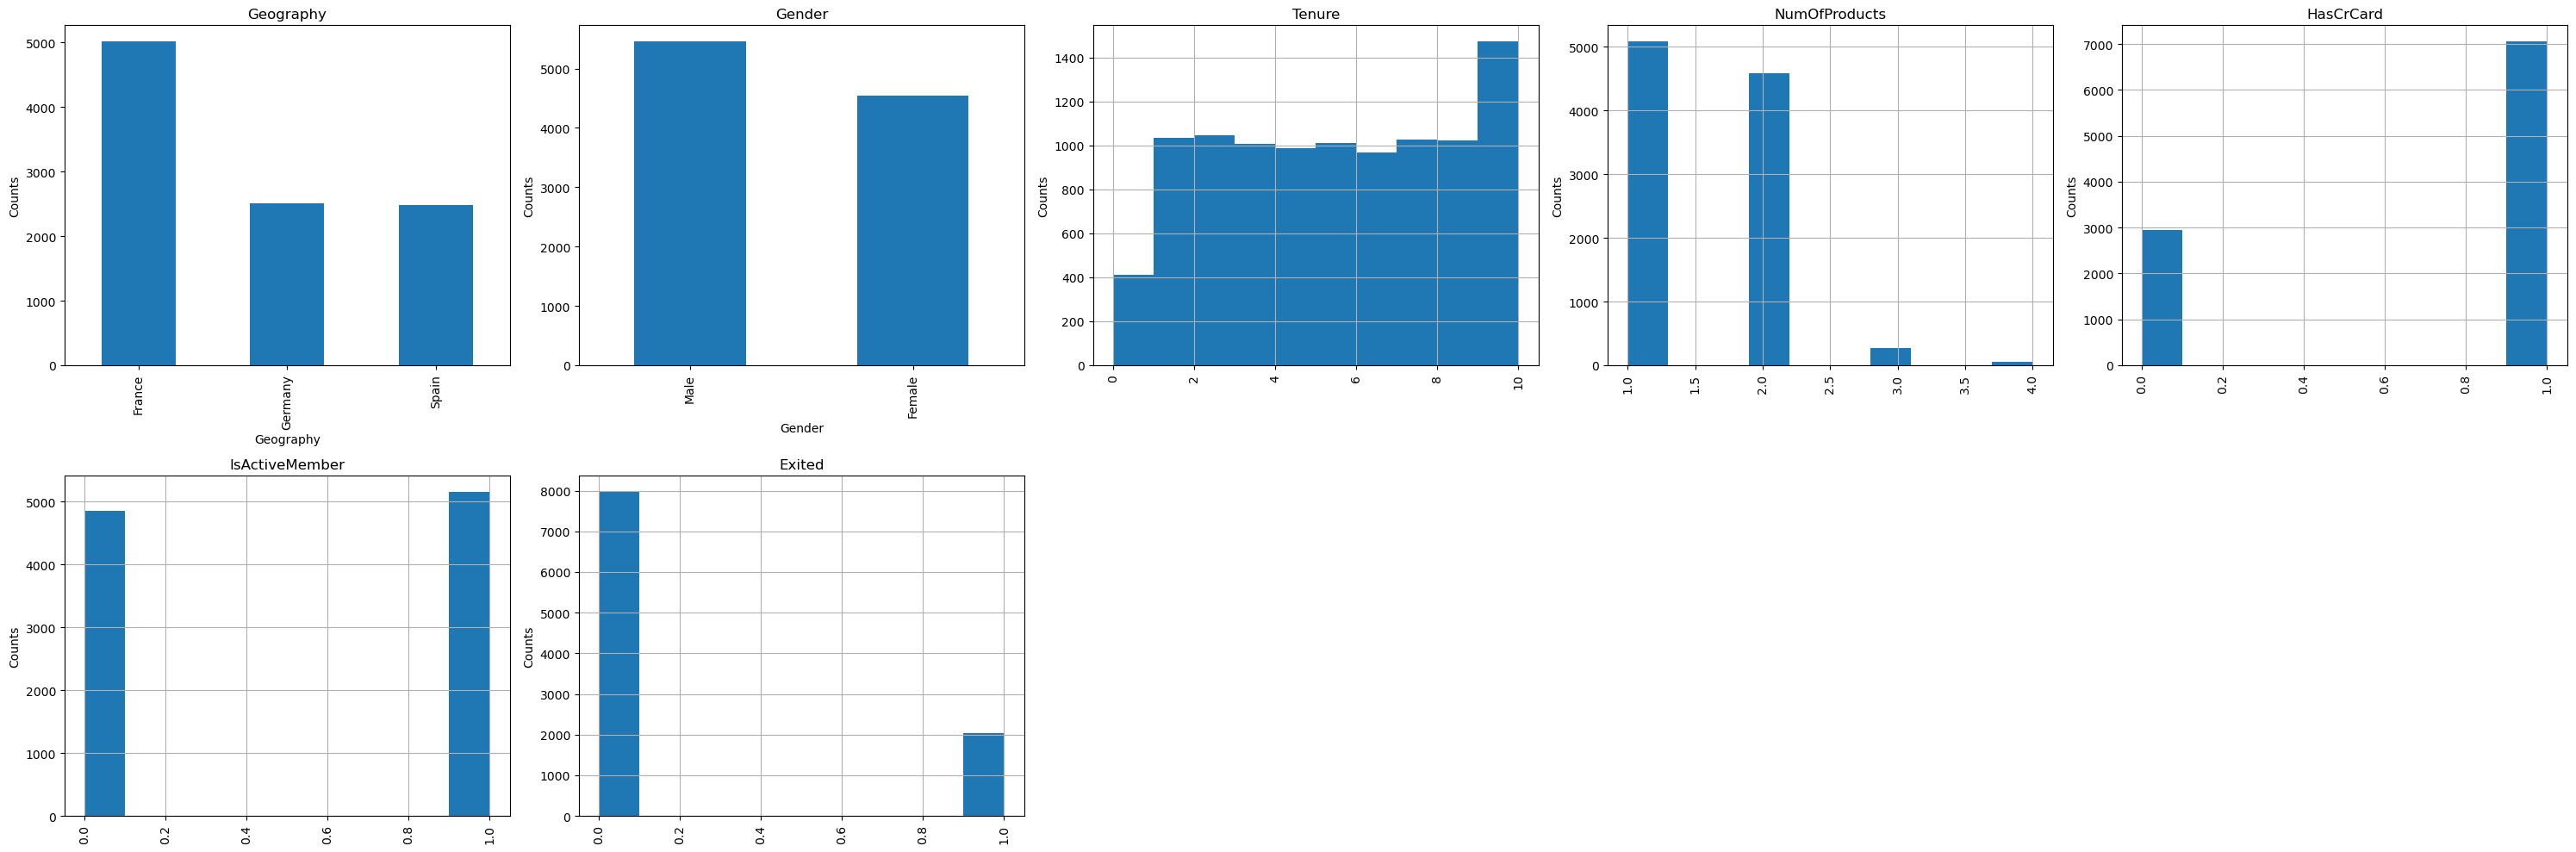

In [10]:
# Step 11: Display distribution graphs
plotPerColumnDistribution(df, 10, 5)

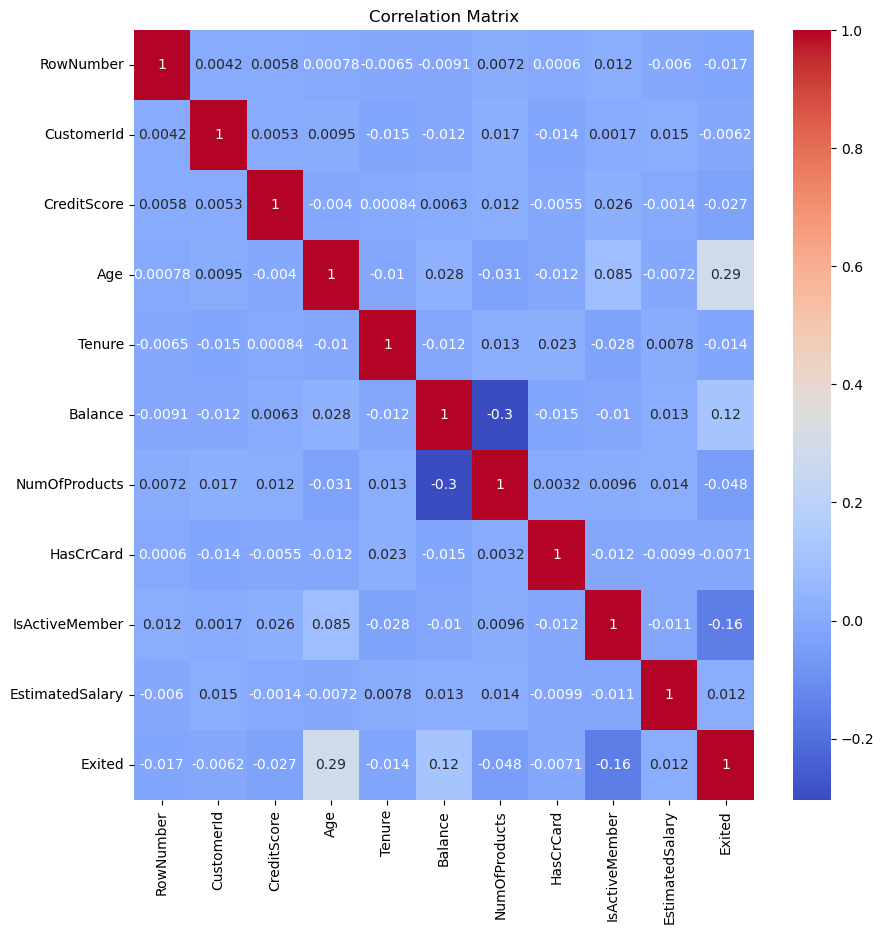

In [11]:
# Step 12: Display correlation matrix
plotCorrelationMatrix(df, 10)

In [ ]:


# Step 13: Display scatter matrix
plotScatterMatrix(df, 10)

print("\nEDA Completed Successfully")
